# 03 - Evaluation and explainability

**Issues:** #15 (complete evaluation, this section). Threshold, SHAP, fairness, the `loan_grade` study and the final test evaluation (#16 to #20) will be added below as they are done.

**Rules**
- The **test set is not used here**. It stays untouched until issue #20.
- The model is the one defined in `src/models/final.py` (default LightGBM, no calibrator), fitted on the training set and evaluated on the **validation set**.
- **Caveat on the validation set:** it has already been used several times to compare models (baseline, selected features, LightGBM, tuned LightGBM, calibrators). The intervals below capture the **sampling noise** of this set only; they do not remove the optimism that selection can introduce. The unbiased estimate will come from the test set in issue #20.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.clean import load_clean_split
from src.features.preprocessing import get_xy
from src.models.bootstrap import bootstrap_metrics, paired_difference, point_estimates, summarize_intervals
from src.models.final import build_final_model
from src.models.zoo import build_model

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
REPORTS = ROOT / "reports"
(REPORTS / "figures").mkdir(parents=True, exist_ok=True)
N_BOOT, THRESHOLD = 1000, 0.5

## 1. Final model and scores on the validation set

In [2]:
X_train, y_train = get_xy(load_clean_split("train"))
X_val, y_val = get_xy(load_clean_split("val"))

final_model = build_final_model(n_jobs=1).fit(X_train, y_train)
baseline = build_model("logistic", "selected", n_jobs=1).fit(X_train, y_train)   # the logistic reference, same features
scores = {
    "lightgbm": final_model.predict_proba(X_val)[:, 1],
    "logistic": baseline.predict_proba(X_val)[:, 1],
}
print(f"validation: {len(y_val)} rows, {int(y_val.sum())} defaults ({y_val.mean():.4f}) | threshold used for recall and precision: {THRESHOLD}")

estimates = {name: point_estimates(y_val, s, THRESHOLD) for name, s in scores.items()}
replicates = bootstrap_metrics(y_val, scores, n_boot=N_BOOT, threshold=THRESHOLD)   # same resampled rows for both models
print(f"{N_BOOT} bootstrap resamples done")

validation: 6482 rows, 1418 defaults (0.2188) | threshold used for recall and precision: 0.5


1000 bootstrap resamples done


## 2. Metrics with 95% bootstrap intervals

ROC AUC, PR AUC, KS and Brier score do not depend on a threshold. Recall and precision are given at the 0.5 **reference** threshold; the cost-based threshold is chosen in issue #16. "Precision at 80% recall" is the best precision reachable while keeping at least 80% of the defaults, a threshold-free operating point.

In [3]:
tables = {name: summarize_intervals(replicates[name], estimates[name]) for name in scores}
display(tables["lightgbm"].round(4))
print("logistic regression (same features), for reference:")
display(tables["logistic"].round(4))

long = pd.concat({name: t for name, t in tables.items()}, names=["model", "metric"]).reset_index()
long.round(4).to_csv(REPORTS / "validation_evaluation.csv", index=False)

,estimate,ci_low,ci_high
roc_auc,0.9459,0.9381,0.9528
pr_auc,0.9049,0.8926,0.9155
ks,0.7595,0.7406,0.7812
brier,0.0514,0.0472,0.0559
recall,0.7525,0.7298,0.7741
precision,0.9544,0.9409,0.9656
precision_at_recall80,0.8341,0.7764,0.8885


logistic regression (same features), for reference:


,estimate,ci_low,ci_high
roc_auc,0.8779,0.8668,0.8875
pr_auc,0.7261,0.7018,0.7469
ks,0.6089,0.5885,0.6349
brier,0.1029,0.0985,0.1083
recall,0.5501,0.5243,0.5748
precision,0.7436,0.7150,0.7703
precision_at_recall80,0.5245,0.4957,0.5640


## 3. Confusion matrix at the 0.5 reference threshold

,predicted: no default,predicted: default
actual: no default,5013,51
actual: default,351,1067


defaults caught (recall): 0.752 | defaults missed: 0.248 | good customers refused: 0.010 | flagged customers that default (precision): 0.954 | cleared customers that stay good: 0.935


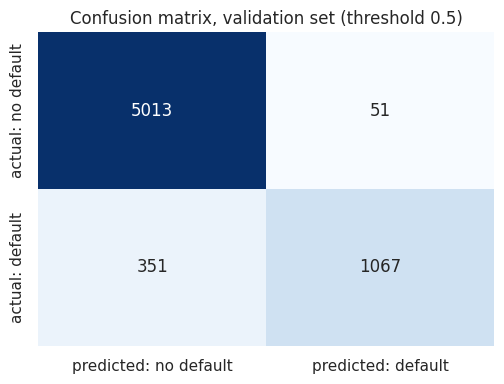

In [4]:
pred = scores["lightgbm"] >= THRESHOLD
actual = y_val.to_numpy() == 1
tn, fp = int((~pred & ~actual).sum()), int((pred & ~actual).sum())
fn, tp = int((~pred & actual).sum()), int((pred & actual).sum())

cm = pd.DataFrame([[tn, fp], [fn, tp]], index=["actual: no default", "actual: default"], columns=["predicted: no default", "predicted: default"])
display(cm)
print(f"defaults caught (recall): {tp / (tp + fn):.3f} | defaults missed: {fn / (tp + fn):.3f} | good customers refused: {fp / (fp + tn):.3f} | flagged customers that default (precision): {tp / (tp + fp):.3f} | cleared customers that stay good: {tn / (tn + fn):.3f}")

fig, ax = plt.subplots(figsize=(5.2, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"Confusion matrix, validation set (threshold {THRESHOLD})")
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "final_confusion_matrix.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. Curves and score distribution

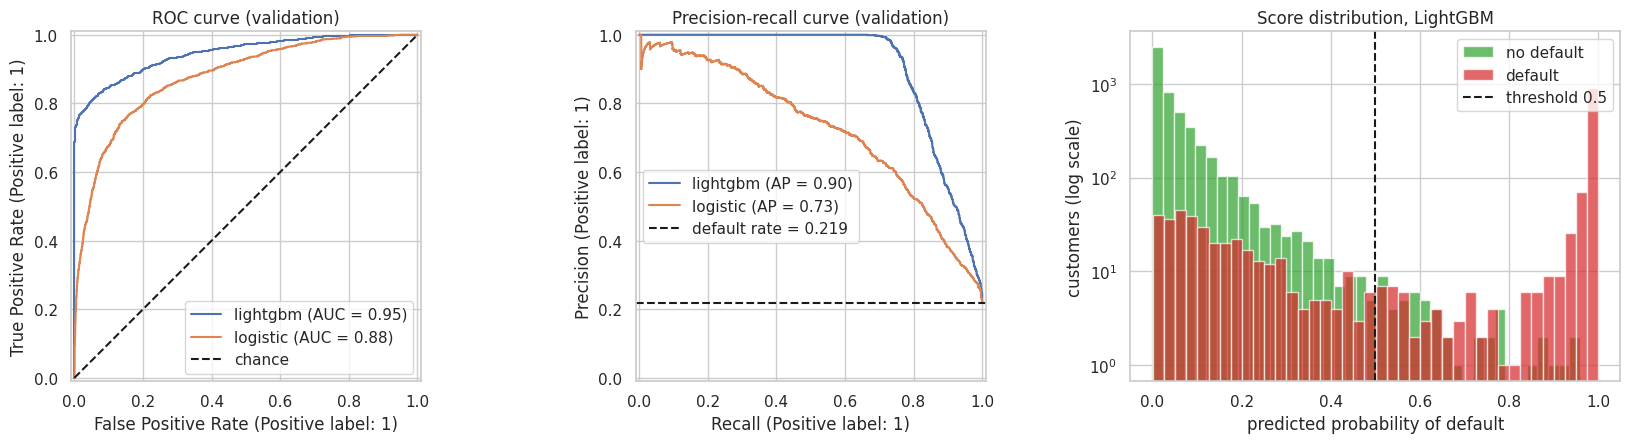

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for name in ("lightgbm", "logistic"):
    RocCurveDisplay.from_predictions(y_val, scores[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, scores[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="chance"); axes[0].set_title("ROC curve (validation)"); axes[0].legend()
axes[1].axhline(y_val.mean(), color="k", linestyle="--", label=f"default rate = {y_val.mean():.3f}"); axes[1].set_title("Precision-recall curve (validation)"); axes[1].legend()

p = scores["lightgbm"]
axes[2].hist(p[~actual], bins=40, alpha=0.7, label="no default", color="#2ca02c")
axes[2].hist(p[actual], bins=40, alpha=0.7, label="default", color="#d62728")
axes[2].axvline(THRESHOLD, color="k", linestyle="--", label=f"threshold {THRESHOLD}")
axes[2].set_yscale("log"); axes[2].set_xlabel("predicted probability of default"); axes[2].set_ylabel("customers (log scale)")
axes[2].set_title("Score distribution, LightGBM"); axes[2].legend()
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "final_evaluation.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. LightGBM against the logistic regression, with paired intervals

In [6]:
diff = paired_difference(replicates["lightgbm"], replicates["logistic"], estimates["lightgbm"], estimates["logistic"])
display(diff.round(4))
print("For the Brier score a lower value is better, so a negative difference favors LightGBM.")
diff.round(4).rename_axis("metric").to_csv(REPORTS / "validation_differences.csv")

,difference,ci_low,ci_high,share_a_higher
roc_auc,0.0680,0.0603,0.0766,1.0
pr_auc,0.1788,0.1611,0.1982,1.0
ks,0.1506,0.1284,0.1725,1.0
brier,-0.0516,-0.0553,-0.0478,0.0
recall,0.2024,0.1783,0.2278,1.0
precision,0.2108,0.1849,0.2367,1.0
precision_at_recall80,0.3096,0.2576,0.3515,1.0


For the Brier score a lower value is better, so a negative difference favors LightGBM.


### Evaluation summary (validation set, 6,482 customers, 1,418 defaults)

**Final model, default LightGBM, 95% bootstrap intervals (1,000 resamples)**

- **Ranking:** ROC AUC 0.946 [0.938, 0.953], PR AUC 0.905 [0.893, 0.915], KS 0.759 [0.741, 0.781].
- **Probabilities:** Brier score 0.0514 [0.0472, 0.0559].
- **At the 0.5 reference threshold:** recall 0.752 [0.730, 0.774] and precision 0.954 [0.941, 0.966]. The best precision reachable at 80% recall is 0.834 [0.776, 0.888]; this interval is much wider because few customers determine that operating point.
- **Confusion matrix at 0.5:** 1,067 of the 1,418 defaults are caught and 351 are missed; 51 of the 5,064 good customers are refused (1.0%). Among the 5,364 customers cleared, 351 default (6.5%).

**Against the logistic regression with the same features (paired intervals)**

- PR AUC +0.179 [0.161, 0.198], ROC AUC +0.068 [0.060, 0.077], KS +0.151 [0.128, 0.172], Brier score -0.052 [-0.055, -0.048] (lower is better). LightGBM is ahead on every metric in all 1,000 resamples.

**What the curves show**

- The precision stays close to 1 up to about 70% recall, then falls: most defaults are found with almost no false alarm, but about a quarter of the defaults (351 of 1,418) get a score below 0.5, in the range of most good customers. That group is the main weakness and a natural target for the explanations (issue #17) and the fairness analysis (issue #18).
- At 0.5 the model misses 24.7% of the defaults while refusing only 1.0% of the good customers. Since a missed default is assumed to cost about five times more than a refused good customer, a lower threshold will probably be cheaper. This is a hypothesis for issue #16.

**Limits**

- The validation set was already used to compare models, so the intervals only reflect its sampling noise and do not remove selection optimism. The test set (issue #20) will give the unbiased estimate.
- The very high scores probably reflect how this public dataset was built (it looks synthetic); they should not be expected on a real portfolio.